# Manual round 3: reserve-price bidding

Simulates the two-bid auction (B1, B2) against a crowd of other players to choose bids that maximise expected profit.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import warnings

np.random.seed(42)

# --- Market parameters ---
MIN_R, MAX_R, STEP = 670, 920, 5
FAIR_VALUE = 920
B1_OPTIMAL = 791
N_PLAYERS = 4000

# --- Simulation parameters ---
N_SIM_B1 = 100_000
N_SIM_B2 = 50_000

# --- Competitor B2 prior breakdown (must sum to 1.0) ---
PRIOR_EXACT_NASH   = 0.10   # bid exactly at Nash
PRIOR_TIGHT_NASH   = 0.25   # normal around Nash, sd=TIGHT_NASH_SD
PRIOR_ABOVE_NASH   = 0.49   # normal around Nash + ABOVE_NASH_OFFSET, sd=ABOVE_NASH_SD
PRIOR_RANDOM       = 0.01   # uniform over [MIN_R, MAX_R]
PRIOR_GRIEF        = 0.15   # point mass at MIN_R or MAX_R

assert abs(PRIOR_EXACT_NASH + PRIOR_TIGHT_NASH + PRIOR_ABOVE_NASH + PRIOR_RANDOM + PRIOR_GRIEF - 1.0) < 1e-9, \
    "Prior weights must sum to 1.0"

# --- Prior shape parameters ---
TIGHT_NASH_SD      = 5      # std dev for tight Nash cluster
ABOVE_NASH_OFFSET  = 15     # how much above Nash the aggressive cluster centers
ABOVE_NASH_SD      = 10     # std dev for above-Nash cluster

Reserve prices: [670 675 680 685 690 695 700 705 710 715 720 725 730 735 740 745 750 755
 760 765 770 775 780 785 790 795 800 805 810 815 820 825 830 835 840 845
 850 855 860 865 870 875 880 885 890 895 900 905 910 915 920]
N counterparties: 51


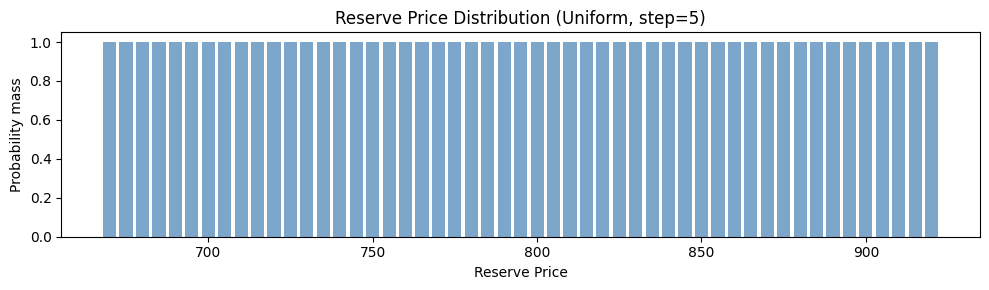

In [2]:
reserves = np.arange(MIN_R, MAX_R + STEP, STEP)
print(f"Reserve prices: {reserves}")
print(f"N counterparties: {len(reserves)}")

plt.figure(figsize=(10, 3))
plt.bar(reserves, np.ones(len(reserves)), width=4, color='steelblue', alpha=0.7)
plt.title("Reserve Price Distribution (Uniform, step=5)")
plt.xlabel("Reserve Price")
plt.ylabel("Probability mass")
plt.tight_layout()
plt.show()

# B1

Optimal single bid (Monte Carlo): 791
Expected profit per counterparty: 63.4383


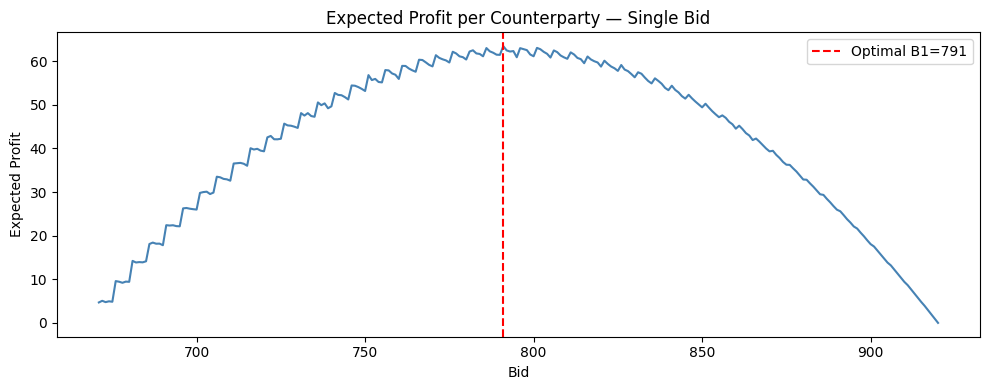

In [3]:
def simulate_single_bid(b1, n_sim=N_SIM_B1):
    """Sample random reserve prices and compute average profit for a single bid."""
    reserves_drawn = np.random.choice(reserves, size=n_sim)
    traded = reserves_drawn < b1
    profit = traded * (FAIR_VALUE - b1)
    return profit.mean()

b1_range = np.arange(MIN_R + 1, MAX_R + 1)
single_bid_profits = [simulate_single_bid(b) for b in b1_range]

best_b1 = b1_range[np.argmax(single_bid_profits)]
print(f"Optimal single bid (Monte Carlo): {best_b1}")
print(f"Expected profit per counterparty: {max(single_bid_profits):.4f}")

plt.figure(figsize=(10, 4))
plt.plot(b1_range, single_bid_profits, color='steelblue')
plt.axvline(best_b1, color='red', linestyle='--', label=f'Optimal B1={best_b1}')
plt.title("Expected Profit per Counterparty — Single Bid")
plt.xlabel("Bid")
plt.ylabel("Expected Profit")
plt.legend()
plt.tight_layout()
plt.show()

# B2

In [4]:
def sample_competitor_bids_vectorized(n_sim, n_competitors, nash_b2):
    """
    Sample competitor B2 bids using the prior defined in Cell 0.
    Returns shape (n_sim, n_competitors).
    """
    rolls = np.random.random((n_sim, n_competitors))
    bids = np.empty_like(rolls)

    cum = 0
    # Exact Nash
    m = rolls < (cum := cum + PRIOR_EXACT_NASH)
    bids[m] = nash_b2

    # Tight Nash cluster
    prev, cum = cum, cum + PRIOR_TIGHT_NASH
    m = (rolls >= prev) & (rolls < cum)
    bids[m] = np.random.normal(nash_b2, TIGHT_NASH_SD, m.sum())

    # Above Nash
    prev, cum = cum, cum + PRIOR_ABOVE_NASH
    m = (rolls >= prev) & (rolls < cum)
    bids[m] = np.random.normal(nash_b2 + ABOVE_NASH_OFFSET, ABOVE_NASH_SD, m.sum())

    # Random
    prev, cum = cum, cum + PRIOR_RANDOM
    m = (rolls >= prev) & (rolls < cum)
    bids[m] = np.random.uniform(MIN_R, MAX_R, m.sum())

    # Grief
    m = rolls >= cum
    bids[m] = np.random.choice([MIN_R, MAX_R], m.sum())

    return np.clip(bids, MIN_R, MAX_R)


def simulate_with_penalty_fast(b2_range, n_players, nash_b2, n_sim=N_SIM_B2):
    """
    Fully vectorized simulation over all b2 values simultaneously.
    Competitor bids drawn from prior centered on nash_b2.
    """
    b2_arr = b2_range.astype(float)  # (n_b2,)

    bids = sample_competitor_bids_vectorized(n_sim, n_players - 1, nash_b2)  # (n_sim, n_players-1)

    comp_sum = bids.sum(axis=1)  # (n_sim,)
    avg_b2 = (comp_sum[:, None] + b2_arr[None, :]) / n_players  # (n_sim, n_b2)

    eligible = reserves[reserves >= B1_OPTIMAL]
    r = np.random.choice(eligible, size=n_sim)  # (n_sim,)

    no_trade    = r[:, None] >= b2_arr[None, :]
    above_mean  = b2_arr[None, :] > avg_b2
    raw_profit  = FAIR_VALUE - b2_arr  # (n_b2,)

    penalty = ((FAIR_VALUE - avg_b2) / np.where(
        raw_profit[None, :] == 0, 1, raw_profit[None, :]
    )) ** 3

    profit = np.where(
        no_trade, 0.0,
        np.where(above_mean, raw_profit[None, :], raw_profit[None, :] * penalty)
    )
    return profit.mean(axis=0)


def find_nash_with_penalty(n_players, b2_range, n_iter=20, n_sim=N_SIM_B2):
    """
    Iterated best response to find Nash B2 with penalties baked in.
    """
    current_nash = float(b2_range[len(b2_range) // 2])
    print(f"  Starting guess: {current_nash}")

    for i in range(n_iter):
        profits = simulate_with_penalty_fast(b2_range, n_players, nash_b2=current_nash, n_sim=n_sim)
        new_nash = float(b2_range[np.argmax(profits)])
        print(f"  Iter {i+1}: Nash B2 = {new_nash} (was {current_nash:.1f})")
        if abs(new_nash - current_nash) < 1:
            print("  Converged.")
            break
        current_nash = new_nash

    return new_nash

Finding Nash B2 (N=4000 players)...
  Starting guess: 856.0
  Iter 1: Nash B2 = 856.0 (was 856.0)
  Converged.

Nash B2 (with penalty): 856.0


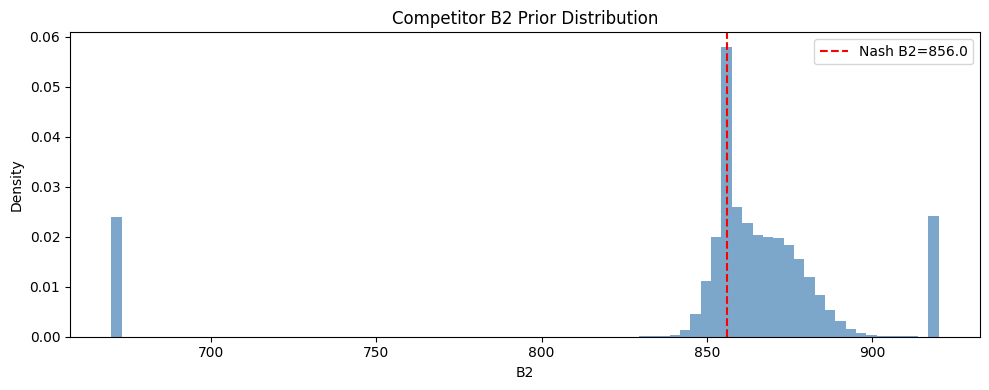

Mean competitor B2  : 853.59
Median competitor B2: 862.26
Std competitor B2   : 56.14


In [5]:
b2_range_pen = np.arange(B1_OPTIMAL + 1, MAX_R)

print(f"Finding Nash B2 (N={N_PLAYERS} players)...")
nash_b2 = find_nash_with_penalty(N_PLAYERS, b2_range_pen)
print(f"\nNash B2 (with penalty): {nash_b2}")

# Visualize prior centered on Nash
sample_bids = sample_competitor_bids_vectorized(10_000, N_PLAYERS - 1, nash_b2).flatten()

plt.figure(figsize=(10, 4))
plt.hist(sample_bids, bins=80, color='steelblue', alpha=0.7, density=True)
plt.axvline(nash_b2, color='red', linestyle='--', label=f'Nash B2={nash_b2}')
plt.title("Competitor B2 Prior Distribution")
plt.xlabel("B2"); plt.ylabel("Density")
plt.legend(); plt.tight_layout(); plt.show()

print(f"Mean competitor B2  : {sample_bids.mean():.2f}")
print(f"Median competitor B2: {np.median(sample_bids):.2f}")
print(f"Std competitor B2   : {sample_bids.std():.2f}")

Optimal B2 (N=4000 players): 856
Expected B2 profit per counterparty: 31.7019


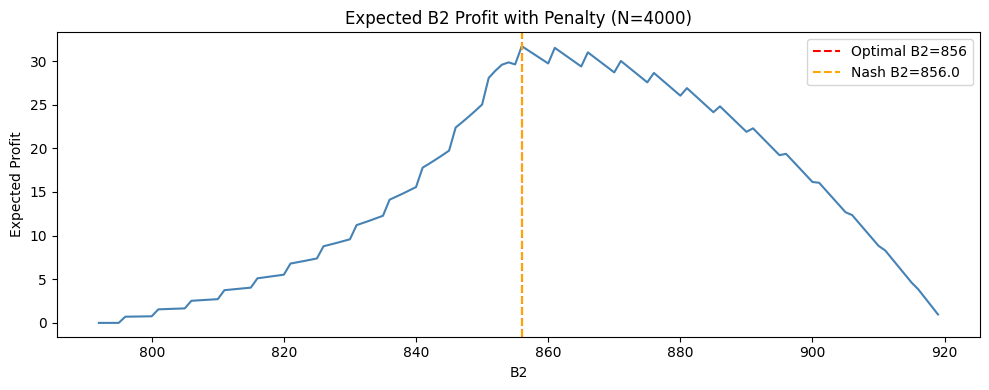

In [6]:
penalized_profits = simulate_with_penalty_fast(b2_range_pen, N_PLAYERS, nash_b2)
best_b2 = b2_range_pen[np.argmax(penalized_profits)]

print(f"Optimal B2 (N={N_PLAYERS} players): {best_b2}")
print(f"Expected B2 profit per counterparty: {max(penalized_profits):.4f}")

plt.figure(figsize=(10, 4))
plt.plot(b2_range_pen, penalized_profits, color='steelblue')
plt.axvline(best_b2, color='red', linestyle='--', label=f'Optimal B2={best_b2}')
plt.axvline(nash_b2, color='orange', linestyle='--', label=f'Nash B2={nash_b2}')
plt.title(f"Expected B2 Profit with Penalty (N={N_PLAYERS})")
plt.xlabel("B2"); plt.ylabel("Expected Profit")
plt.legend(); plt.tight_layout(); plt.show()


Scenario: Base (last year's prior)
  Starting guess: 856.0
  Iter 1: Nash B2 = 856.0 (was 856.0)
  Converged.
  → Nash B2=856.0, Optimal B2=856, E[profit]=31.8035

Scenario: More Nash players
  Starting guess: 856.0
  Iter 1: Nash B2 = 861.0 (was 856.0)
  Iter 2: Nash B2 = 862.0 (was 861.0)
  Iter 3: Nash B2 = 866.0 (was 862.0)
  Iter 4: Nash B2 = 866.0 (was 866.0)
  Converged.
  → Nash B2=866.0, Optimal B2=866, E[profit]=30.8245

Scenario: More aggressive players
  Starting guess: 856.0
  Iter 1: Nash B2 = 861.0 (was 856.0)
  Iter 2: Nash B2 = 866.0 (was 861.0)
  Iter 3: Nash B2 = 871.0 (was 866.0)
  Iter 4: Nash B2 = 876.0 (was 871.0)
  Iter 5: Nash B2 = 881.0 (was 876.0)
  Iter 6: Nash B2 = 886.0 (was 881.0)
  Iter 7: Nash B2 = 888.0 (was 886.0)
  Iter 8: Nash B2 = 891.0 (was 888.0)
  Iter 9: Nash B2 = 893.0 (was 891.0)
  Iter 10: Nash B2 = 896.0 (was 893.0)
  Iter 11: Nash B2 = 897.0 (was 896.0)
  Iter 12: Nash B2 = 897.0 (was 897.0)
  Converged.
  → Nash B2=897.0, Optimal B2=897,

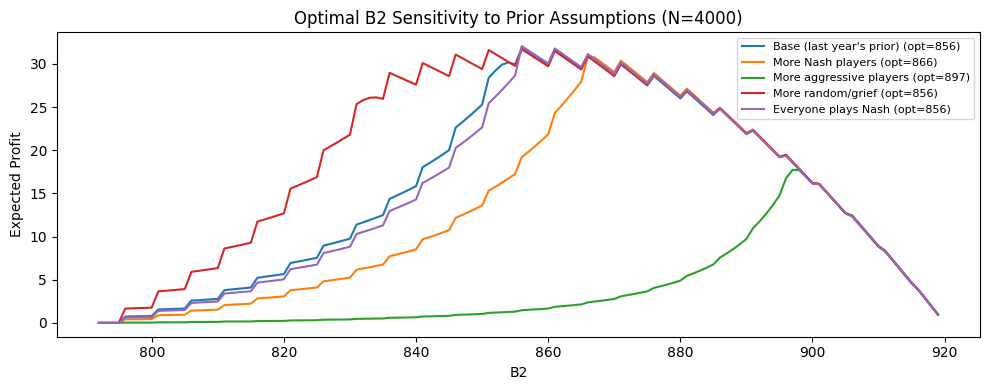

In [7]:
# perfect Nash
# concentrate around the optimal mid-point (tight Nash cluster)
# pick values slightly higher than the GTO price
# pick completely randomly
# intentionally grief

scenarios = {
    "Base (last year's prior)":   (0.10, 0.25, 0.49, 0.01, 0.15),
    "More Nash players":          (0.30, 0.40, 0.25, 0.01, 0.04),
    "More aggressive players":    (0.05, 0.10, 0.75, 0.05, 0.05),
    "More random/grief":          (0.10, 0.15, 0.30, 0.10, 0.35),
    "Everyone plays Nash":        (1.00, 0.00, 0.00, 0.00, 0.00),
}

results = {}

for name, (p_exact, p_tight, p_above, p_rand, p_grief) in scenarios.items():
    # Temporarily override globals
    global PRIOR_EXACT_NASH, PRIOR_TIGHT_NASH, PRIOR_ABOVE_NASH, PRIOR_RANDOM, PRIOR_GRIEF
    PRIOR_EXACT_NASH, PRIOR_TIGHT_NASH, PRIOR_ABOVE_NASH, PRIOR_RANDOM, PRIOR_GRIEF = \
        p_exact, p_tight, p_above, p_rand, p_grief

    print(f"\nScenario: {name}")
    nash_n = find_nash_with_penalty(N_PLAYERS, b2_range_pen, n_sim=20_000)
    profits = simulate_with_penalty_fast(b2_range_pen, N_PLAYERS, nash_n, n_sim=20_000)
    best = b2_range_pen[np.argmax(profits)]
    results[name] = (best, nash_n, max(profits), profits)
    print(f"  → Nash B2={nash_n}, Optimal B2={best}, E[profit]={max(profits):.4f}")

# Restore base prior
PRIOR_EXACT_NASH, PRIOR_TIGHT_NASH, PRIOR_ABOVE_NASH, PRIOR_RANDOM, PRIOR_GRIEF = \
    0.10, 0.25, 0.49, 0.01, 0.15

plt.figure(figsize=(10, 4))
for name, (best, _, _, profits) in results.items():
    plt.plot(b2_range_pen, profits, label=f'{name} (opt={best})')
plt.title(f"Optimal B2 Sensitivity to Prior Assumptions (N={N_PLAYERS})")
plt.xlabel("B2"); plt.ylabel("Expected Profit")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

In [8]:
print("=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Optimal B1              : {B1_OPTIMAL}")
print(f"N Players               : {N_PLAYERS}")
print()
print("Base prior assumptions:")
print(f"  Exact Nash            : {PRIOR_EXACT_NASH:.0%}")
print(f"  Tight Nash cluster    : {PRIOR_TIGHT_NASH:.0%}  (sd={TIGHT_NASH_SD})")
print(f"  Above Nash            : {PRIOR_ABOVE_NASH:.0%}  (offset={ABOVE_NASH_OFFSET}, sd={ABOVE_NASH_SD})")
print(f"  Random                : {PRIOR_RANDOM:.0%}")
print(f"  Grief                 : {PRIOR_GRIEF:.0%}")
print()
print(f"Base Nash B2            : {nash_b2}")
print(f"Base Optimal B2         : {best_b2}")
print()
print("Sensitivity to prior assumptions:")
print(f"  {'Scenario':<30} {'Nash B2':>8} {'Optimal B2':>12} {'E[profit]':>10}")
print("  " + "-" * 64)
for name, (best, nash_n, profit, _) in results.items():
    print(f"  {name:<30} {nash_n:>8} {best:>12} {profit:>10.4f}")
print()
best_b2_values = [best for best, *_ in results.values()]
print(f"Optimal B2 range across scenarios: [{min(best_b2_values)}, {max(best_b2_values)}]")
print(f"→ {'Robust' if max(best_b2_values) - min(best_b2_values) <= 10 else 'Sensitive'} to prior assumptions.")

SUMMARY
Optimal B1              : 791
N Players               : 4000

Base prior assumptions:
  Exact Nash            : 10%
  Tight Nash cluster    : 25%  (sd=5)
  Above Nash            : 49%  (offset=15, sd=10)
  Random                : 1%
  Grief                 : 15%

Base Nash B2            : 856.0
Base Optimal B2         : 856

Sensitivity to prior assumptions:
  Scenario                        Nash B2   Optimal B2  E[profit]
  ----------------------------------------------------------------
  Base (last year's prior)          856.0          856    31.8035
  More Nash players                 866.0          866    30.8245
  More aggressive players           897.0          897    17.7279
  More random/grief                 856.0          856    31.7056
  Everyone plays Nash               856.0          856    32.0544

Optimal B2 range across scenarios: [856, 897]
→ Sensitive to prior assumptions.
